In [1]:
import os
os.chdir("/home/hashalike/Belgeler/Yazılım/Projeler/Music Taste & Age")
os.getcwd()

'/home/hashalike/Belgeler/Yazılım/Projeler/Music Taste & Age'

In [2]:
from transformers import pipeline
from src.data_collection import enrich_tracks
from src.data_cleaning import clean_track_info, clean_tracks
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay ,accuracy_score,precision_score,recall_score,f1_score,classification_report


/home/hashalike/Belgeler/Yazılım/Projeler/Music Taste & Age/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
classifier=pipeline(\
    "zero-shot-classification",\
    model= "MoritzLaurer/bge-m3-zeroshot-v2.0"\
)

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9268.27it/s]


In [ ]:
labels= ["Music","Non-Music"]

df= enrich_tracks("duzeniduzenadam",50,4)

df=df.drop_duplicates(subset=["name","artist"]).reset_index()

df


Error, track not found: Anyma-ARTBAT - Argy - Korolova I Melodic Techno & Progressive House Mix 2026 4K!
Error, track not found: Timur Soykan anlattı-Sarayda çok büyük bir güç kavgası var...!
Error, track not found: MURPHYS DIESEL-5 MASSIVE Farm Tractors BURIED in Quicksand! Can We Save Them?!
Error, track not found: Barış Özcan-You could spot the next neutrino!
Error, track not found: Barış Özcan-Are aliens writing to each other in neutrinos?!
Error, track not found: Barış Özcan-So what good is all this to us?!
Error, track not found: Barış Özcan-Seeing the Milky Way without light!
Error, track not found: Barış Özcan-Can a neutrino pass through a black hole?!
Error, track not found: Barış Özcan-A neutrino's return address, read for the first time!
Error, track not found: Barış Özcan-Years of waiting, then Ernie and Bert!
Error, track not found: Barış Özcan-Is IceCube an earthquake weapon?!
Error, track not found: Barış Özcan-86 holes, 5,160 eyes!
Error, track not found: Barış Özcan-A 

,index,name,artist,album_,date,timestamp,track_mbid,duration,listeners,playcount,artist_mbid,album_info,tags
0,0,ARTBAT - Argy - Korolova I Melodic Techno & Pr...,Anyma,,"13 Oct 2026, 12:39",1791895166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,What did Alan Turing do after Bletchley Park?,Veritasium,,"13 Oct 2026, 08:36",1791880598,None,0,34,36,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
2,2,The Naval Enigma,Veritasium,,"13 Oct 2026, 08:33",1791880422,None,0,35,38,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
3,3,The Bombe,Breaking Enigma,,"13 Oct 2026, 08:26",1791879990,None,0,64,70,NaN,None,[]
4,4,How Enigma’s Flaws Were Exploited,Veritasium,,"13 Oct 2026, 08:18",1791879513,None,0,67,74,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
5,5,Who was Alan Turing?,Veritasium,,"13 Oct 2026, 08:14",1791879278,None,0,72,79,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
6,6,Trying To Decrypt An Enigma Message,Veritasium,,"13 Oct 2026, 08:08",1791878928,None,0,77,83,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
7,7,The First Codebreakers Who Broke Enigma,Veritasium,,"13 Oct 2026, 08:05",1791878713,None,0,82,91,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
8,8,The Secret Spy Mansion,Veritasium,,"13 Oct 2026, 08:02",1791878574,None,0,84,91,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]
9,9,How did Enigma work?,Veritasium,,"13 Oct 2026, 07:56",1791878179,None,0,103,109,cacc18a6-04c5-4708-b312-15c9c1d5aea5,None,[]


In [15]:
true_label = [
    "Music",      # 0 - ARTBAT - Argy - Korolova I Melodic Techno & Pr...
    "Non-Music",  # 1 - What did Alan Turing do after Bletchley Park?
    "Non-Music",  # 2 - The Naval Enigma
    "Non-Music",  # 3 - The Bombe
    "Non-Music",  # 4 - How Enigma’s Flaws Were Exploited
    "Non-Music",  # 5 - Who was Alan Turing?
    "Non-Music",  # 6 - Trying To Decrypt An Enigma Message
    "Non-Music",  # 7 - The First Codebreakers Who Broke Enigma
    "Non-Music",  # 8 - The Secret Spy Mansion
    "Non-Music",  # 9 - How did Enigma work?
    "Non-Music",  # 10 - Who invented Enigma?
    "Non-Music",  # 11 - Sarayda çok büyük bir güç kavgası var...
    "Non-Music",  # 12 - 5 MASSIVE Farm Tractors BURIED in Quicksand!
    "Non-Music",  # 13 - You could spot the next neutrino
    "Non-Music",  # 14 - Are aliens writing to each other in neutrinos?
    "Non-Music",  # 15 - So what good is all this to us?
    "Non-Music",  # 16 - Seeing the Milky Way without light
    "Non-Music",  # 17 - Can a neutrino pass through a black hole?
    "Non-Music",  # 18 - A neutrino's return address, read for the first time
    "Non-Music",  # 19 - Years of waiting, then Ernie and Bert
    "Non-Music",  # 20 - Is IceCube an earthquake weapon?
    "Non-Music",  # 21 - 86 holes, 5,160 eyes
    "Non-Music",  # 22 - A lost year, then the ice surprised them
    "Non-Music",  # 23 - Turning Antarctica into a detector
    "Non-Music",  # 24 - I have done a terrible thing
    "Non-Music",  # 25 - The mailman that never bumps into anything
    "Non-Music",  # 26 - A pool table and an erased address
    "Non-Music",  # 27 - How many years does sunlight take to leave the...
    "Non-Music",  # 28 - Wi-Fi goes through walls, so why can't light?
    "Non-Music"   # 29 - This banana is emitting antimatter right now
]

In [16]:
df["true_label"]= true_label

In [21]:
df.columns

Index(['name', 'artist', 'album', 'timestamp', 'duration', 'text',
       'true_label', 'predict_label', 'predict_score'],
      dtype='str')

In [25]:
results=[]
data= {}
for i in range(len(df)):
    album=str(df["album"][i])
    timestamp= str(df["timestamp"][i])
    name= str(df["name"][i])
    artist= df["artist"][i]
    text= str(name + " - " + artist+ " - " + album + " - " + timestamp)
    result= classifier(text,candidate_labels=labels)

    data={
        "name": df["name"][i],
        "artist": df["artist"][i],
        "album": df["album"][i],
        "timestamp": df["timestamp"][i],
        "duration": df["duration"][i],
        "text":text,
        "true_label": df["true_label"][i],
        "predict_label": result["labels"][0],
        "predict_score": result["scores"][0]
        }

    results.append(data)



In [26]:
dataf= pd.DataFrame(results)
dataf.to_csv("/home/hashalike/Belgeler/Yazılım/Projeler/Music Taste & Age/notebooks/classifier_test.csv", index=False, encoding="utf-8-sig")


df= pd.read_csv("/home/hashalike/Belgeler/Yazılım/Projeler/Music Taste & Age/notebooks/classifier_test.csv")

cm = confusion_matrix(df["true_label"], df["predict_label"], labels=["Music","Non-Music"])

print(cm)

[[ 1  0]
 [ 6 23]]


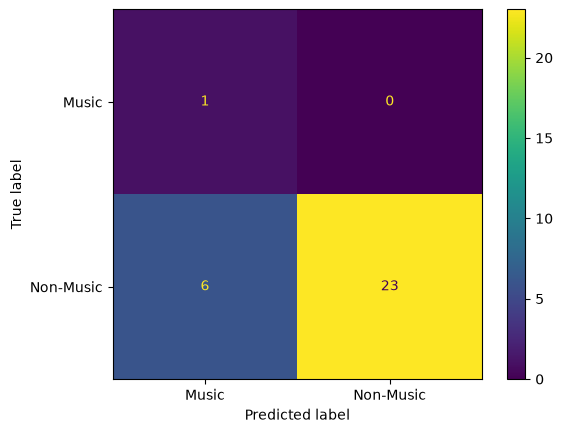

In [27]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Music", "Non-Music"]
).plot()



In [28]:
accuracy= accuracy_score(df["true_label"],df["predict_label"])
precision= precision_score(df["true_label"],df["predict_label"],pos_label="Music")
recall= recall_score(df["true_label"],df["predict_label"],pos_label="Music")
f1= f1_score(df["true_label"],df["predict_label"],pos_label="Music")



print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


Accuracy:  0.8000
Precision: 0.1429
Recall:    1.0000
F1-score:  0.2500


In [30]:

fail= df[(df["true_label"]=="Non-Music") & (df["predict_label"]=="Music")]
fail

,name,artist,album,timestamp,duration,text,true_label,predict_label,predict_score
2,The Naval Enigma,Veritasium,NaN,1791880422,0.0,The Naval Enigma - Veritasium - nan - 1791880422,Non-Music,Music,0.895842
3,The Bombe,Breaking Enigma,NaN,1791879990,0.0,The Bombe - Breaking Enigma - nan - 1791879990,Non-Music,Music,0.930395
8,The Secret Spy Mansion,Veritasium,NaN,1791878574,0.0,The Secret Spy Mansion - Veritasium - nan - 17...,Non-Music,Music,0.712432
13,You could spot the next neutrino,Barış Özcan,NaN,1791844605,NaN,You could spot the next neutrino - Barış Özcan...,Non-Music,Music,0.839800
16,Seeing the Milky Way without light,Barış Özcan,NaN,1791844415,NaN,Seeing the Milky Way without light - Barış Özc...,Non-Music,Music,0.823186
19,"Years of waiting, then Ernie and Bert",Barış Özcan,NaN,1791844155,NaN,"Years of waiting, then Ernie and Bert - Barış ...",Non-Music,Music,0.930458
